In [1]:
!pip install ultralytics


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 23.0 MB/s eta 0:00:00


In [2]:
import os
import cv2
import yaml
import pandas as pd
import matplotlib.pyplot as plt
from ultralytics import YOLO
from sklearn.model_selection import train_test_split

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
train_images_dir = "/content/drive/My Drive/archive (2)/data/training_images"
test_images_dir = "/content/drive/My Drive/archive (2)/data/testing_images"
bbox_csv_path = "/content/drive/My Drive/archive (2)/data/train_solution_bounding_boxes (1).csv"

In [ ]:
import numpy as np

In [ ]:
def apply_kernel_filter(img):
    kernel = np.array([
        [1, 2, 1],
        [2, 4, 2],
        [1, 2, 1]
    ], dtype=np.float32)
    kernel = kernel / 16.0
    filtered_img = cv2.filter2D(img, -1, kernel)
    return filtered_img

In [ ]:
import pandas as pd

In [ ]:
bbox_df = pd.read_csv(bbox_csv_path)
print("Bounding boxes data sample:")
print(bbox_df.head())
print(f"Total bounding boxes: {len(bbox_df)}")

Bounding boxes data sample:
             image        xmin        ymin        xmax        ymax
0   vid_4_1000.jpg  281.259045  187.035071  327.727931  223.225547
1  vid_4_10000.jpg   15.163531  187.035071  120.329957  236.430180
2  vid_4_10040.jpg  239.192475  176.764801  361.968162  236.430180
3  vid_4_10020.jpg  496.483358  172.363256  630.020260  231.539575
4  vid_4_10060.jpg   16.630970  186.546010  132.558611  238.386422
Total bounding boxes: 559


In [ ]:
def prepare_yolo_data(train_images_dir, bbox_df, output_dir="/content/yolo_data"):

    os.makedirs(os.path.join(output_dir, "images/train"), exist_ok=True)
    os.makedirs(os.path.join(output_dir, "images/val"), exist_ok=True)
    os.makedirs(os.path.join(output_dir, "labels/train"), exist_ok=True)
    os.makedirs(os.path.join(output_dir, "labels/val"), exist_ok=True)

    unique_images = bbox_df['image'].unique()
    print(f"Total unique images: {len(unique_images)}")

    train_images, val_images = train_test_split(unique_images, test_size=0.2, random_state=42)

    def convert_to_yolo_format(image_name, image_bboxes, images_output_dir, labels_output_dir):
        img_path = os.path.join(train_images_dir, image_name)

        if not os.path.exists(img_path):
            print(f"Warning: Image {img_path} not found")
            return

        img = cv2.imread(img_path)
        if img is None:
            print(f"Warning: Could not read image {img_path}")
            return

        img = apply_kernel_filter(img)

        img_height, img_width = img.shape[:2]

        label_filename = os.path.splitext(image_name)[0] + '.txt'
        label_path = os.path.join(labels_output_dir, label_filename)

        with open(label_path, 'w') as f:
            for _, bbox in image_bboxes.iterrows():
                xmin = bbox['xmin']
                ymin = bbox['ymin']
                xmax = bbox['xmax']
                ymax = bbox['ymax']

                x_center = ((xmin + xmax) / 2) / img_width
                y_center = ((ymin + ymax) / 2) / img_height
                width = (xmax - xmin) / img_width
                height = (ymax - ymin) / img_height

                x_center = max(0, min(1, x_center))
                y_center = max(0, min(1, y_center))
                width = max(0, min(1, width))
                height = max(0, min(1, height))

                f.write(f"0 {x_center:.6f} {y_center:.6f} {width:.6f} {height:.6f}\n")

        output_img_path = os.path.join(images_output_dir, image_name)
        cv2.imwrite(output_img_path, img)

        return True

    print("Processing training images...")
    train_count = 0
    for img_name in train_images:
        img_bboxes = bbox_df[bbox_df['image'] == img_name]
        if convert_to_yolo_format(
            img_name,
            img_bboxes,
            os.path.join(output_dir, "images/train"),
            os.path.join(output_dir, "labels/train")
        ):
            train_count += 1

    print("Processing validation images...")
    val_count = 0
    for img_name in val_images:
        img_bboxes = bbox_df[bbox_df['image'] == img_name]
        if convert_to_yolo_format(
            img_name,
            img_bboxes,
            os.path.join(output_dir, "images/val"),
            os.path.join(output_dir, "labels/val")
        ):
            val_count += 1

    print(f"Data preparation completed!")
    print(f"Training images: {train_count}")
    print(f"Validation images: {val_count}")
    print(f"Output directory: {output_dir}")
    return output_dir

yolo_data_dir = prepare_yolo_data(train_images_dir, bbox_df)


Total unique images: 355
Processing training images...
Processing validation images...
Data preparation completed!
Training images: 284
Validation images: 71
Output directory: /content/yolo_data


In [ ]:
def check_prepared_data(data_dir):
    train_images_dir = os.path.join(data_dir, "images/train")
    train_labels_dir = os.path.join(data_dir, "labels/train")
    val_images_dir = os.path.join(data_dir, "images/val")
    val_labels_dir = os.path.join(data_dir, "labels/val")

    print("Checking prepared data...")
    print(f"Train images: {len(os.listdir(train_images_dir))}")
    print(f"Train labels: {len(os.listdir(train_labels_dir))}")
    print(f"Val images: {len(os.listdir(val_images_dir))}")
    print(f"Val labels: {len(os.listdir(val_labels_dir))}")

    if os.listdir(train_labels_dir):
        sample_label = os.listdir(train_labels_dir)[0]
        sample_label_path = os.path.join(train_labels_dir, sample_label)
        print(f"\nSample label file ({sample_label}):")
        with open(sample_label_path, 'r') as f:
            print(f.read())

check_prepared_data(yolo_data_dir)

Checking prepared data...
Train images: 284
Train labels: 284
Val images: 71
Val labels: 71

Sample label file (vid_4_21500.txt):
0 0.524240 0.544321 0.185962 0.111969
0 0.111433 0.588723 0.202605 0.131274



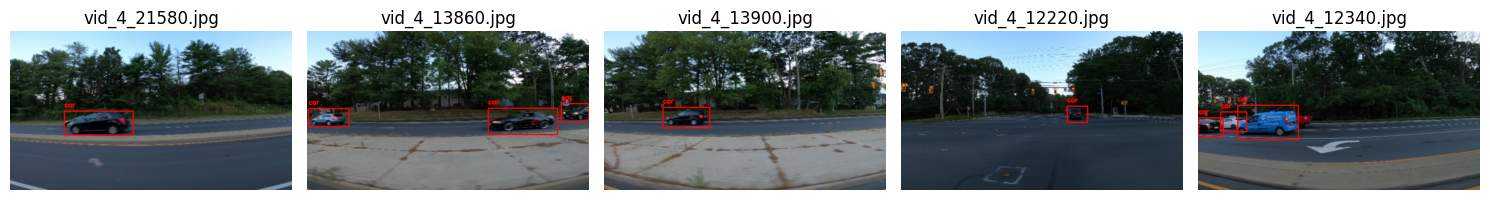

In [ ]:
def visualize_random_images_with_bboxes(data_dir, num_images=5):

    images_dir = os.path.join(data_dir, "images/train")
    labels_dir = os.path.join(data_dir, "labels/train")

    image_files = [f for f in os.listdir(images_dir) if f.endswith(('.jpg', '.png', '.jpeg'))]

    if not image_files:
        print("No images found in the directory!")
        return

    selected_images = random.sample(image_files, min(num_images, len(image_files)))

    fig, axes = plt.subplots(1, len(selected_images), figsize=(15, 5))
    if len(selected_images) == 1:
        axes = [axes]

    for i, img_name in enumerate(selected_images):
        img_path = os.path.join(images_dir, img_name)
        img = cv2.imread(img_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        label_path = os.path.join(labels_dir, os.path.splitext(img_name)[0] + '.txt')

        if os.path.exists(label_path):
            with open(label_path, 'r') as f:
                lines = f.readlines()

            for line in lines:
                class_id, x_center, y_center, width, height = map(float, line.strip().split())

                img_height, img_width = img.shape[:2]
                x_center_px = x_center * img_width
                y_center_px = y_center * img_height
                width_px = width * img_width
                height_px = height * img_height

                xmin = int(x_center_px - width_px / 2)
                ymin = int(y_center_px - height_px / 2)
                xmax = int(x_center_px + width_px / 2)
                ymax = int(y_center_px + height_px / 2)

                cv2.rectangle(img, (xmin, ymin), (xmax, ymax), (255, 0, 0), 2)
                cv2.putText(img, 'car', (xmin, ymin-10), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 0, 0), 2)

        axes[i].imshow(img)
        axes[i].set_title(img_name)
        axes[i].axis('off')

    plt.tight_layout()
    plt.show()

visualize_random_images_with_bboxes(yolo_data_dir)

In [ ]:
config_content = f"""
path: {yolo_data_dir}
train: images/train
val: images/val

nc: 1
names: ['car']
"""

config_path = os.path.join(yolo_data_dir, 'dataset.yaml')
with open(config_path, 'w') as f:
    f.write(config_content)

print(f"Config file created at: {config_path}")

Config file created at: /content/yolo_data/dataset.yaml


In [ ]:
model = YOLO('yolov8n.pt')
results = model.train(
    data=config_path,
    epochs=15,
    imgsz=640,
    batch=8,
    name='car_detection_yolo',
    project='/content/drive/MyDrive/car_detection_training'
)

Ultralytics 8.3.236 🚀 Python-3.12.12 torch-2.9.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/yolo_data/dataset.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=15, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=False, name=car_detection_yolo4, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=100, perspective=0.0, pl

In [ ]:
from deep_sort_realtime.deepsort_tracker import DeepSort

In [ ]:
from deep_sort_realtime.deepsort_tracker import DeepSort

tracker = DeepSort(max_age=30, n_init=3, nms_max_overlap=1.0)

def track_objects(model_path, video_path=None, image_path=None, save_path=None):
    model = YOLO(model_path)

    if video_path:
        cap = cv2.VideoCapture(video_path)
    elif image_path:
        cap = None
        frame = cv2.imread(image_path)
    else:
        raise ValueError("Provide video_path or image_path")

    while True:
        if cap:
            ret, frame = cap.read()
            if not ret:
                break

        results = model(frame)
        result = results[0]

        detections = []
        for det in result.boxes.data.cpu().numpy():
            x1, y1, x2, y2, conf, cls = det
            detections.append(([x1, y1, x2 - x1, y2 - y1], conf, int(cls)))

        tracks = tracker.update_tracks(detections, frame=frame)

        for track in tracks:
            if not track.is_confirmed():
                continue
            track_id = track.track_id
            x1, y1, x2, y2 = map(int, track.to_ltrb())

            cv2.rectangle(frame, (x1, y1), (x2, y2), (0,255,0), 2)
            cv2.putText(frame, f"ID: {track_id}", (x1, y1-10),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0,255,0), 2)

        plt.figure(figsize=(8,8))
        plt.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
        plt.axis('off')
        plt.show()

        if not cap:
            break

    if cap:
        cap.release()

    if save_path:
        cv2.imwrite(save_path, frame)

In [ ]:
from google.colab import files

def test_on_video(model_path):
    print(" Upload a video file (MP4 / AVI) to test tracking:")
    uploaded = files.upload()
    video_path = list(uploaded.keys())[0]
    print(f"Video uploaded: {video_path}")

    # Load model
    model = YOLO(model_path)
    tracker = DeepSort(max_age=30, n_init=3, nms_max_overlap=1.0)

    cap = cv2.VideoCapture(video_path)

    # Output video writer
    fourcc = cv2.VideoWriter_fourcc(*"mp4v")
    out = cv2.VideoWriter("tracked_output.mp4", fourcc,
                          int(cap.get(cv2.CAP_PROP_FPS)),
                          (int(cap.get(3)), int(cap.get(4))))

    print("Processing video...")

    while True:
        ret, frame = cap.read()
        if not ret:
            break

        results = model(frame)
        dets = []
        for det in results[0].boxes.data.cpu().numpy():
            x1, y1, x2, y2, conf, cls = det
            dets.append(([x1, y1, x2 - x1, y2 - y1], conf, int(cls)))

        tracks = tracker.update_tracks(dets, frame=frame)

        for track in tracks:
            if not track.is_confirmed():
                continue
            track_id = track.track_id
            x1, y1, x2, y2 = map(int, track.to_ltrb())
            cv2.rectangle(frame, (x1, y1), (x2, y2), (0,255,0), 2)
            cv2.putText(frame, f"ID {track_id}", (x1, y1 - 10),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0,255,0), 2)

        out.write(frame)

    cap.release()
    out.release()

    print("Video tracking completed!")
    print("Download your output:")
    files.download("tracked_output.mp4")

In [ ]:
test_on_video(best_model_path)

📤 Upload a video file (MP4 / AVI) to test tracking:


Saving tracking.mp4 to tracking.mp4
Video uploaded: tracking.mp4
Processing video...

0: 640x416 3 cars, 41.7ms
Speed: 2.0ms preprocess, 41.7ms inference, 1.3ms postprocess per image at shape (1, 3, 640, 416)

0: 640x416 4 cars, 6.7ms
Speed: 2.5ms preprocess, 6.7ms inference, 1.2ms postprocess per image at shape (1, 3, 640, 416)

0: 640x416 3 cars, 6.6ms
Speed: 2.5ms preprocess, 6.6ms inference, 1.3ms postprocess per image at shape (1, 3, 640, 416)

0: 640x416 1 car, 6.0ms
Speed: 2.6ms preprocess, 6.0ms inference, 1.4ms postprocess per image at shape (1, 3, 640, 416)

0: 640x416 4 cars, 5.9ms
Speed: 2.4ms preprocess, 5.9ms inference, 1.1ms postprocess per image at shape (1, 3, 640, 416)

0: 640x416 3 cars, 5.7ms
Speed: 2.3ms preprocess, 5.7ms inference, 1.1ms postprocess per image at shape (1, 3, 640, 416)

0: 640x416 5 cars, 5.8ms
Speed: 2.3ms preprocess, 5.8ms inference, 1.1ms postprocess per image at shape (1, 3, 640, 416)

0: 640x416 5 cars, 6.6ms
Speed: 2.6ms preprocess, 6.6ms inf

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>